In [32]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt


def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q3_c.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [33]:
class CIFAR10Dataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


def get_clean_loaders(seed=260007, data_dir="./data", batch_size=1024):
    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train, y_train = all_images[train_idx], all_labels[train_idx]
    X_val, y_val = all_images[val_idx], all_labels[val_idx]
    X_test, y_test = raw_test.data, np.array(raw_test.targets)

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_loader = DataLoader(
        CIFAR10Dataset(X_train, y_train, transform=transform),
        batch_size=batch_size, shuffle=False, num_workers=2
    )
    val_loader = DataLoader(
        CIFAR10Dataset(X_val, y_val, transform=transform),
        batch_size=batch_size, shuffle=False, num_workers=2
    )
    test_loader = DataLoader(
        CIFAR10Dataset(X_test, y_test, transform=transform),
        batch_size=batch_size, shuffle=False, num_workers=2
    )

    return train_loader, val_loader, test_loader

In [34]:
class ConvAutoencoder(nn.Module):
    """Exact same architecture as Q3 Parts (a) and (b)."""
    def __init__(self, bottleneck_dim: int):
        super().__init__()
        self.bottleneck_dim = bottleneck_dim

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.encoder_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, bottleneck_dim),
            nn.ReLU(inplace=True)
        )

        self.decoder_fc = nn.Sequential(
            nn.Linear(bottleneck_dim, 128 * 4 * 4),
            nn.ReLU(inplace=True)
        )
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
        )

    def encode(self, x):
        return self.encoder_fc(self.encoder_conv(x))

    def decode(self, z):
        return self.decoder_conv(self.decoder_fc(z).view(-1, 128, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))

In [35]:
def extract_features_and_test_mse(model: nn.Module, train_loader, val_loader, test_loader, device="cpu"):
    model.eval()
    for p in model.parameters():
        p.requires_grad = False

    def get_latents(loader):
        zs, ys = [], []
        with torch.no_grad():
            for x, y in loader:
                x = x.to(device)
                z = model.encode(x)
                zs.append(z.cpu().numpy())
                ys.append(y.numpy())
        return np.concatenate(zs, axis=0), np.concatenate(ys, axis=0)

    Z_train, y_train = get_latents(train_loader)
    Z_val, y_val = get_latents(val_loader)
    Z_test, y_test = get_latents(test_loader)

    criterion = nn.MSELoss(reduction="sum")
    total_loss, total_elements = 0.0, 0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            recon = model(x)
            total_loss += criterion(recon, x).item()
            total_elements += x.numel()
    clean_test_mse = total_loss / total_elements

    return (Z_train, y_train), (Z_val, y_val), (Z_test, y_test), clean_test_mse


def fit_linear_probe(train_tuple, val_tuple, test_tuple, seed=260007):
    Z_train, y_train = train_tuple
    Z_val, y_val = val_tuple
    Z_test, y_test = test_tuple

    scaler = StandardScaler()
    Z_train_s = scaler.fit_transform(Z_train)
    Z_val_s = scaler.transform(Z_val)
    Z_test_s = scaler.transform(Z_test)

    best_c = None
    best_val_acc = -1.0
    best_clf = None

    for c_val in [0.01, 0.1, 1.0, 10.0]:
        clf = LogisticRegression(
            C=c_val, max_iter=500, solver="lbfgs", random_state=seed
        )
        clf.fit(Z_train_s, y_train)
        val_acc = 100.0 * clf.score(Z_val_s, y_val)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_c = c_val
            best_clf = clf

    test_acc = 100.0 * best_clf.score(Z_test_s, y_test)
    return best_c, best_val_acc, test_acc


def plot_recon_vs_class_info(results, save_path="q3_part_c_recon_vs_class_info.png"):
    names = [r["name"] for r in results]
    test_mses = [r["test_mse"] for r in results]
    probe_accs = [r["test_probe_acc"] for r in results]

    x = np.arange(len(names))
    fig, ax1 = plt.subplots(figsize=(9.5, 5.2))

    color1 = "#d95f02"
    bars = ax1.bar(x - 0.18, test_mses, width=0.35, color=color1, alpha=0.85, label="Clean Test Reconstruction MSE (Lower = Better)")
    ax1.set_ylabel("Clean Test Reconstruction MSE", color=color1, fontweight="bold")
    ax1.tick_params(axis="y", labelcolor=color1)
    ax1.set_xticks(x)
    ax1.set_xticklabels(names)
    ax1.set_ylim(0, max(test_mses) * 1.25)

    for bar in bars:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                 f"{bar.get_height():.4f}", ha="center", va="bottom", fontsize=8.5, color=color1)

    ax2 = ax1.twinx()
    color2 = "#1b9e77"
    line = ax2.plot(x + 0.18, probe_accs, color=color2, marker="o", linewidth=2.5, markersize=8,
                    label="Frozen-Encoder Linear Probe Test Acc (Higher = Better)")
    ax2.set_ylabel("Linear Probe Test Accuracy (%)", color=color2, fontweight="bold")
    ax2.tick_params(axis="y", labelcolor=color2)
    ax2.set_ylim(0, max(probe_accs) * 1.25)

    for idx, acc in enumerate(probe_accs):
        ax2.text(x[idx] + 0.18, acc + 1.5, f"{acc:.2f}%", ha="center", va="bottom", fontsize=9, fontweight="bold", color=color2)

    plt.title("Question 3(c): Reconstruction Quality vs. Linearly Readable Class Information (Test Set)")
    ax1.grid(True, axis="y", alpha=0.25)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=8.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

Running Question 3 Part (c) on device: cuda

Probing frozen encoder: CAE-Small (d=32) (cae_d32.pt)...
  Best C=0.01 | Val Probe Acc: 33.42% | Test Probe Acc: 33.47% | Test MSE: 0.236691

Probing frozen encoder: CAE-Medium (d=128) (cae_d128.pt)...
  Best C=0.01 | Val Probe Acc: 39.02% | Test Probe Acc: 38.39% | Test MSE: 0.123978

Probing frozen encoder: CAE-Large (d=512) (cae_d512.pt)...
  Best C=1.0 | Val Probe Acc: 48.48% | Test Probe Acc: 48.95% | Test MSE: 0.077737

Probing frozen encoder: DAE-Large (d=512) (dae_d512.pt)...
  Best C=1.0 | Val Probe Acc: 49.36% | Test Probe Acc: 49.75% | Test MSE: 0.111762

QUESTION 3 PART (c) DELIVERABLES SUMMARY (OFFICIAL TEST SET)
Model                | Bottleneck |  Clean Test MSE |  Val Probe Acc |  Test Probe Acc
--------------------------------------------------------------------------------------
CAE-Small (d=32)     |         32 |        0.236691 |         33.42% |          33.47%
CAE-Medium (d=128)   |        128 |        0.123978 |       

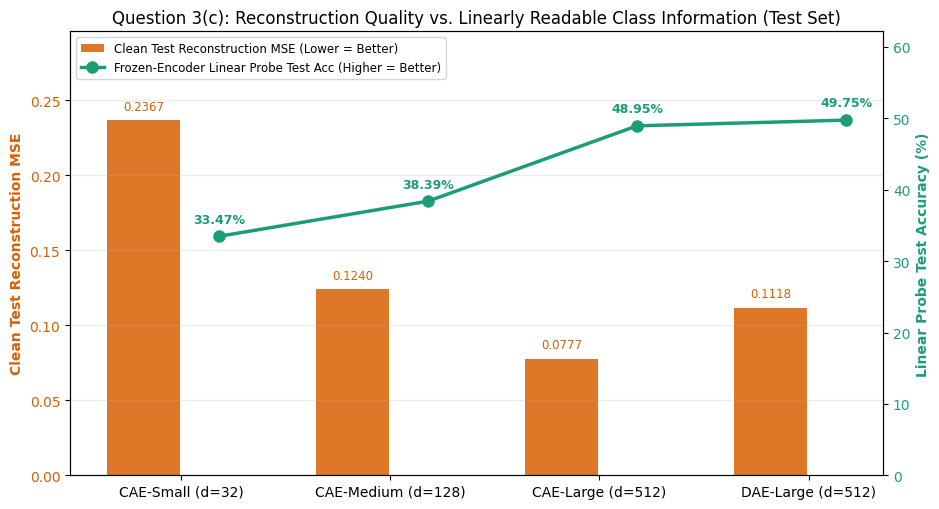

In [36]:
if __name__ == "__main__":
    SEED = 260007
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    logger.info(f"Running Question 3 Part (c) on device: {DEVICE}")

    set_global_seed(SEED)
    train_loader, val_loader, test_loader = get_clean_loaders(seed=SEED)

    model_specs = [
        {"name": "CAE-Small (d=32)",  "dim": 32,  "weights": "cae_d32.pt"},
        {"name": "CAE-Medium (d=128)", "dim": 128, "weights": "cae_d128.pt"},
        {"name": "CAE-Large (d=512)",  "dim": 512, "weights": "cae_d512.pt"},
        {"name": "DAE-Large (d=512)",  "dim": 512, "weights": "dae_d512.pt"},
    ]

    results = []
    for spec in model_specs:
        logger.info(f"\nProbing frozen encoder: {spec['name']} ({spec['weights']})...")
        ae = ConvAutoencoder(bottleneck_dim=spec["dim"]).to(DEVICE)
        ae.load_state_dict(torch.load(spec["weights"], map_location=DEVICE))

        train_tup, val_tup, test_tup, clean_test_mse = extract_features_and_test_mse(
            ae, train_loader, val_loader, test_loader, device=DEVICE
        )

        best_c, val_probe_acc, test_probe_acc = fit_linear_probe(
            train_tup, val_tup, test_tup, seed=SEED
        )
        logger.info(f"  Best C={best_c} | Val Probe Acc: {val_probe_acc:.2f}% | Test Probe Acc: {test_probe_acc:.2f}% | Test MSE: {clean_test_mse:.6f}")

        results.append({
            "name": spec["name"],
            "dim": spec["dim"],
            "test_mse": clean_test_mse,
            "val_probe_acc": val_probe_acc,
            "test_probe_acc": test_probe_acc,
        })

    logger.info("\n" + "=" * 86)
    logger.info("QUESTION 3 PART (c) DELIVERABLES SUMMARY (OFFICIAL TEST SET)")
    logger.info("=" * 86)
    logger.info(f"{'Model':<20} | {'Bottleneck':>10} | {'Clean Test MSE':>15} | {'Val Probe Acc':>14} | {'Test Probe Acc':>15}")
    logger.info("-" * 86)
    for r in results:
        logger.info(f"{r['name']:<20} | {r['dim']:>10d} | {r['test_mse']:>15.6f} | {r['val_probe_acc']:>13.2f}% | {r['test_probe_acc']:>14.2f}%")
    logger.info("=" * 86)

    plot_recon_vs_class_info(results)